In [1]:
#1. Cài đặt thư viện cần thiết
%pip install opencv-python numpy pillow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


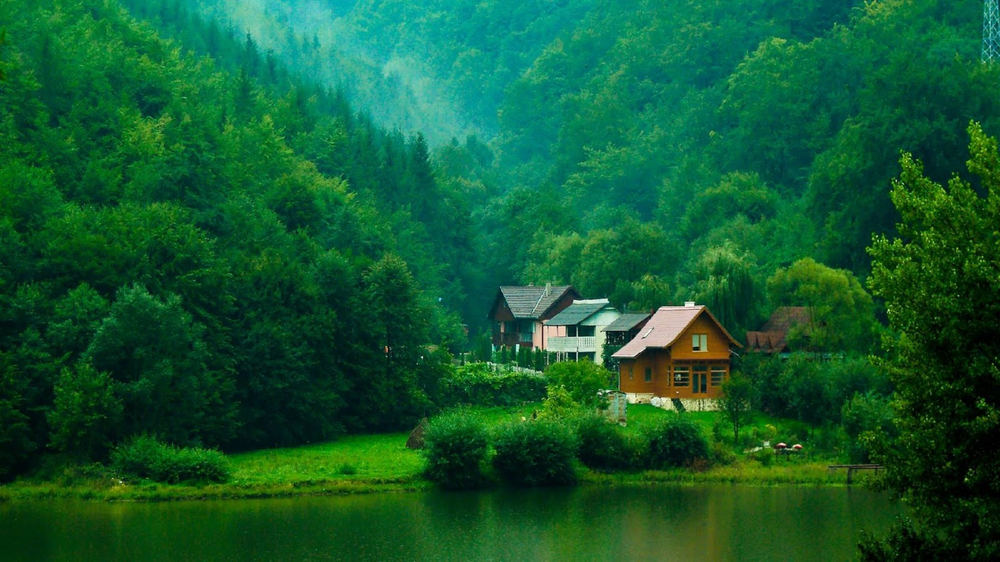

In [3]:
#2. Đọc ảnh
import cv2
import numpy as np
from PIL import Image
from IPython.display import display
img = Image.open('images.jpg').convert('RGB')
anh_goc = np.array(img)
display(img)


Ảnh tăng độ sáng (+50)


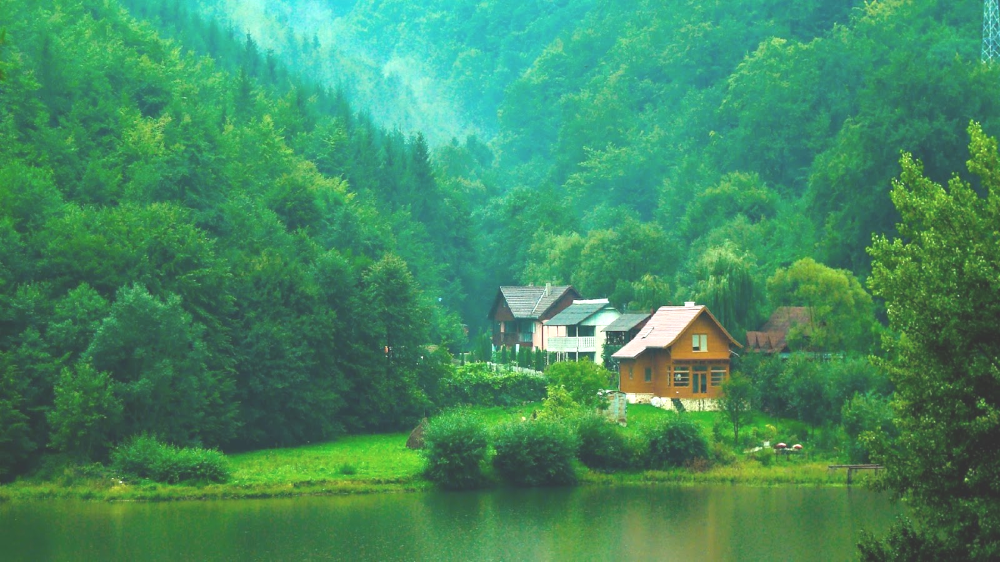

Ảnh giảm độ sáng (-50)


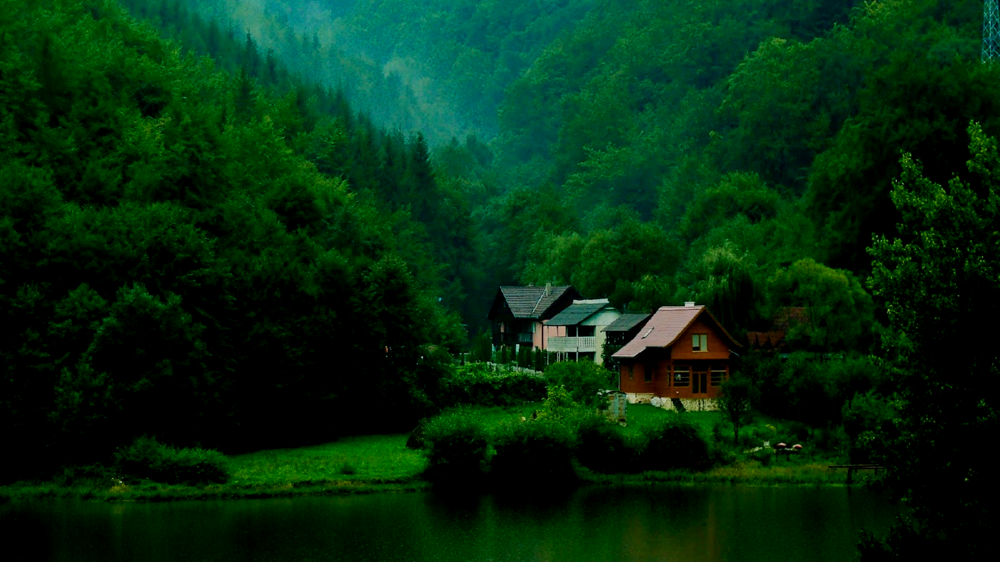

In [8]:
#3. Thay đổi độ sáng
anh_tang_sang = np.clip(anh_goc.astype(np.int16) + 50, 0, 255).astype(np.uint8)
anh_giam_sang = np.clip(anh_goc.astype(np.int16) - 50, 0, 255).astype(np.uint8)
print("Ảnh tăng độ sáng (+50)")
display(Image.fromarray(anh_tang_sang))
print("Ảnh giảm độ sáng (-50)")
display(Image.fromarray(anh_giam_sang))

Ảnh tăng độ tương phản (×1.5)


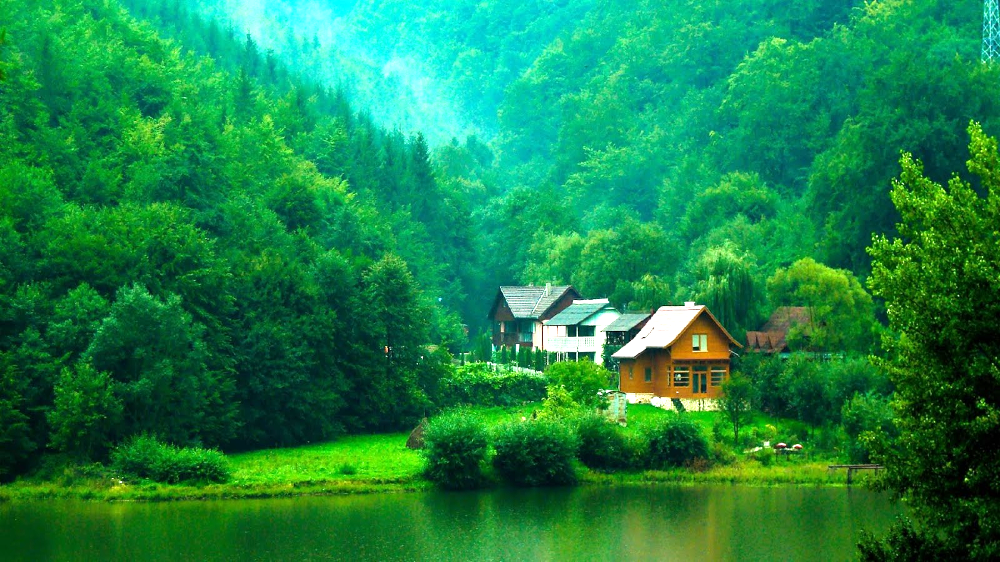

Ảnh giảm độ tương phản (×0.5)


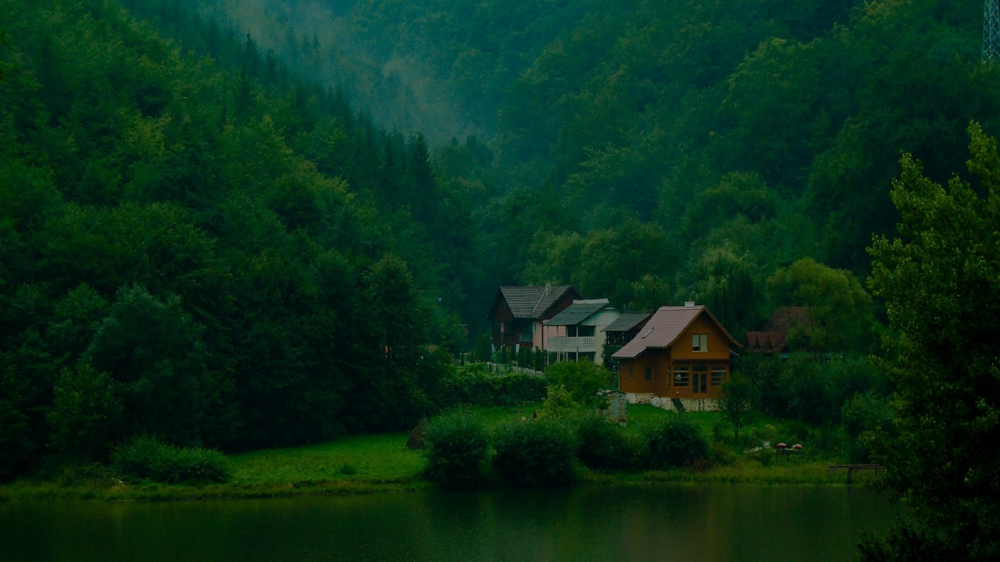

In [9]:
#4. Thay đổi độ tương phản
anh_tang_tuong_phan = np.clip(anh_goc.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)
anh_giam_tuong_phan = np.clip(anh_goc.astype(np.float32) * 0.5, 0, 255).astype(np.uint8)
print("Ảnh tăng độ tương phản (×1.5)")
display(Image.fromarray(anh_tang_tuong_phan))
print("Ảnh giảm độ tương phản (×0.5)")
display(Image.fromarray(anh_giam_tuong_phan))

Ảnh âm bản


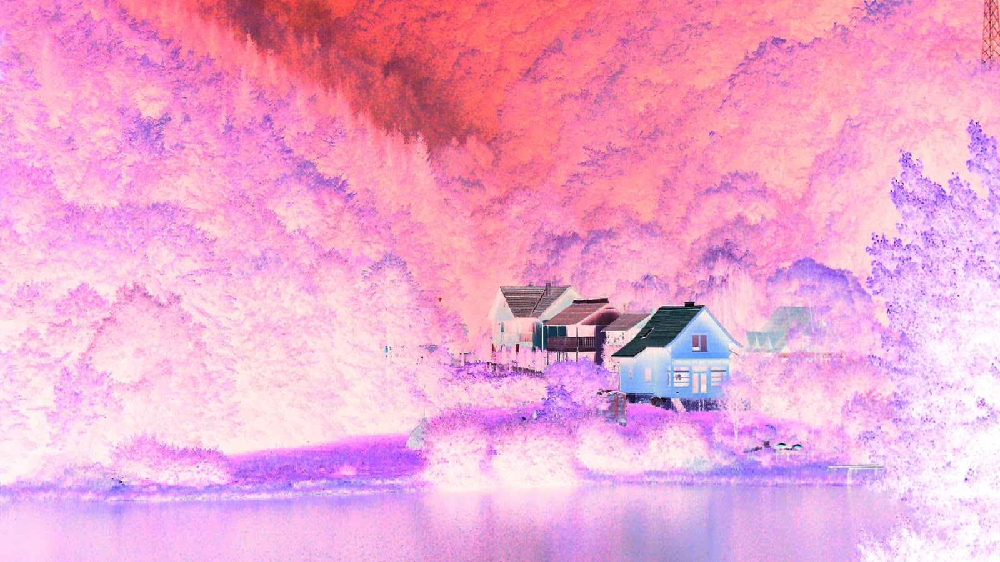

In [10]:
#5. Biến đổi ảnh âm bản
anh_am_ban = 255 - anh_goc
print("Ảnh âm bản")
display(Image.fromarray(anh_am_ban))

Ảnh nhị phân (ngưỡng 128)


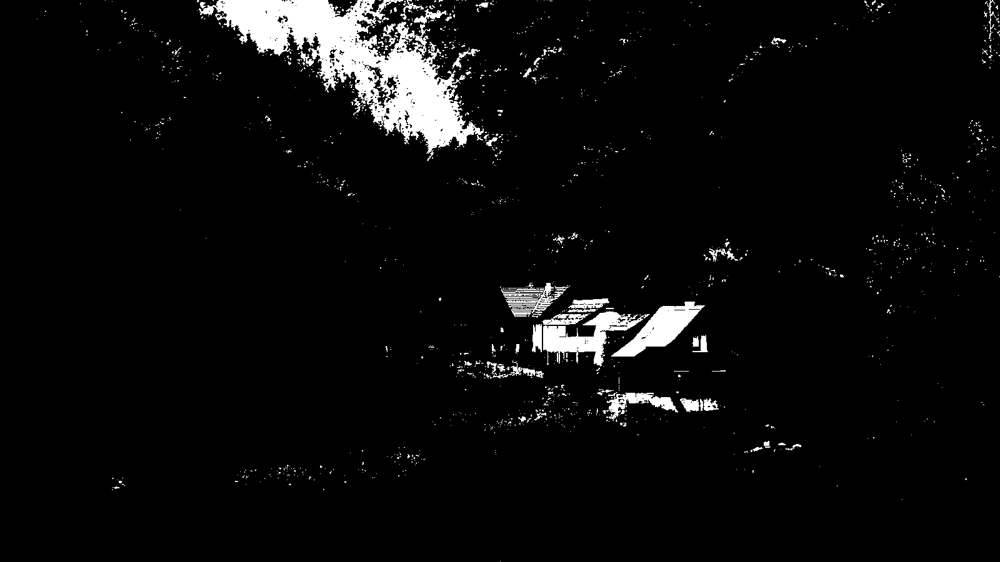

In [11]:
#6. Cắt ngưỡng tạo ảnh nhị phân
anh_xam = cv2.cvtColor(anh_goc, cv2.COLOR_RGB2GRAY)
_, anh_nhi_phan = cv2.threshold(anh_xam, 128, 255, cv2.THRESH_BINARY)
print("Ảnh nhị phân (ngưỡng 128)")
display(Image.fromarray(anh_nhi_phan))

Ảnh sau khi lọc trung bình (9x9)


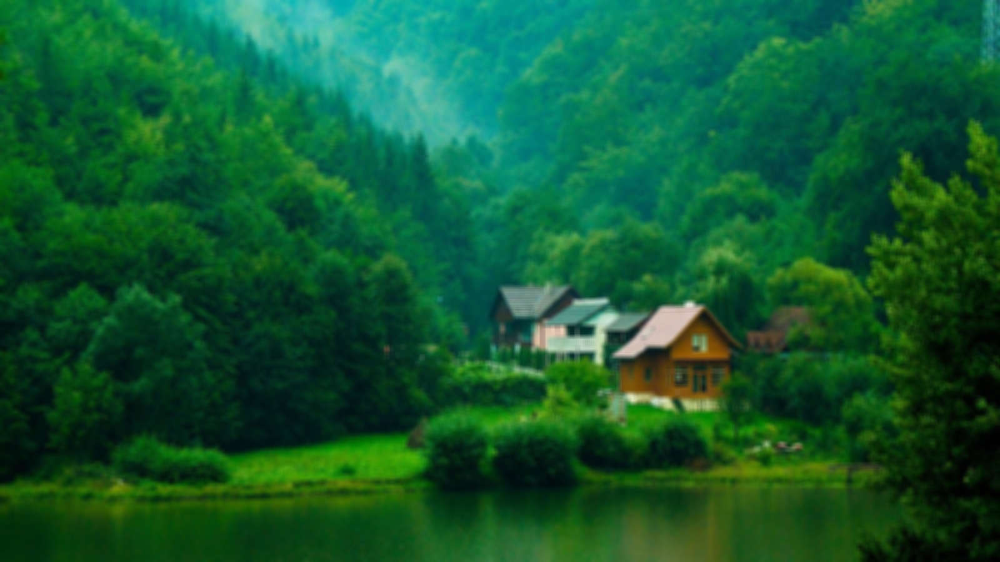

In [12]:
#7. Lọc trung bình
anh_loc_trung_binh = cv2.blur(anh_goc, (9, 9))
print("Ảnh sau khi lọc trung bình (9x9)")
display(Image.fromarray(anh_loc_trung_binh))

Ảnh sau khi lọc Gaussian (9x9)


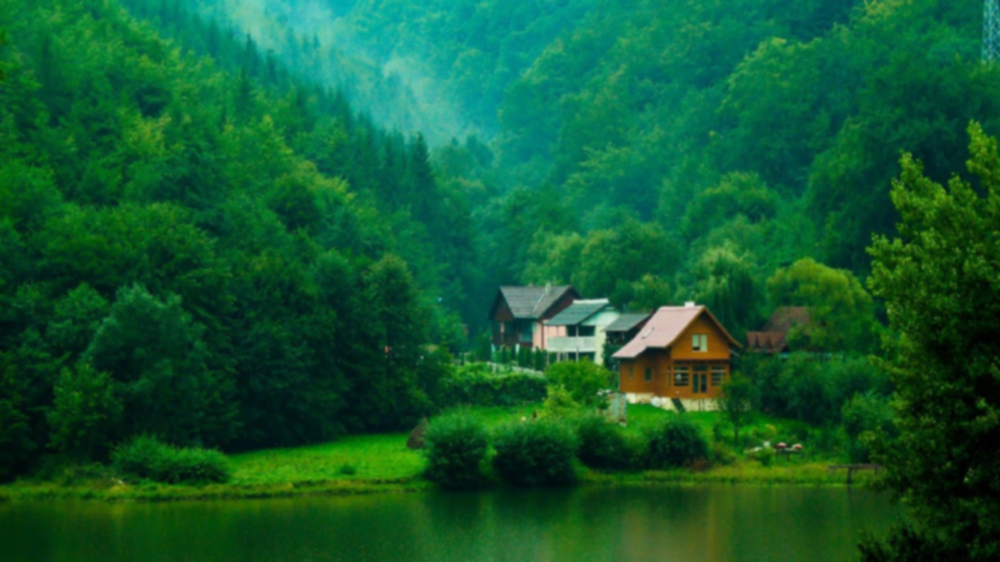

In [14]:
#8. Lọc Gaussian
anh_loc_gaussian = cv2.GaussianBlur(anh_goc, (9, 9), 0)
print("Ảnh sau khi lọc Gaussian (9x9)")
display(Image.fromarray(anh_loc_gaussian))

Ảnh sau khi làm sắc nét


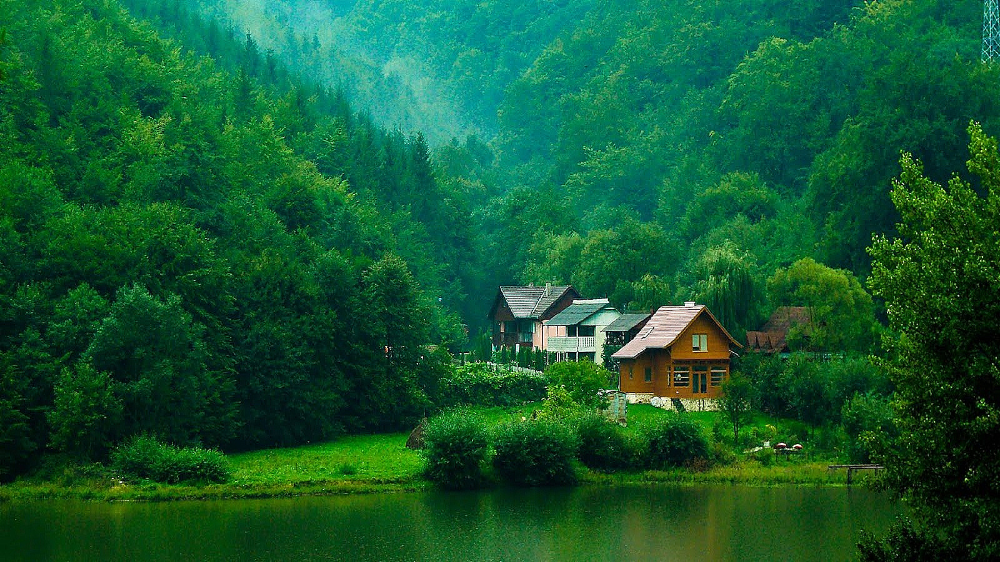

In [21]:
#9. Làm sắc nét ảnh bằng kernel
kernel = np.array([[0, -1, 0],[-1, 5, -1],[0, -1, 0]])
anh_sac_net = cv2.filter2D(anh_goc, -1, kernel)
print("Ảnh sau khi làm sắc nét")
display(Image.fromarray(anh_sac_net))

Ảnh phát hiện cạnh bằng Sobel


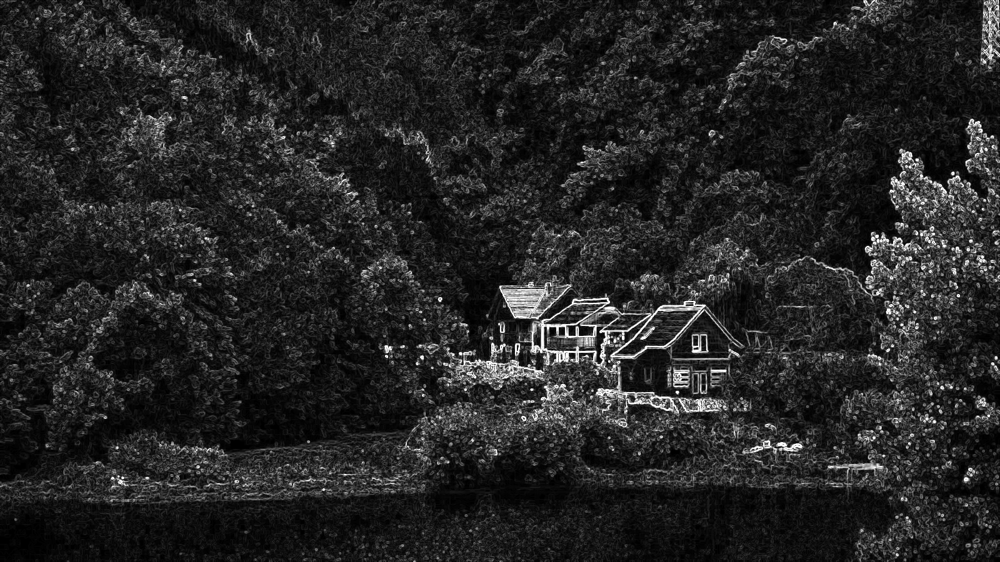

Ảnh phát hiện cạnh bằng Prewitt


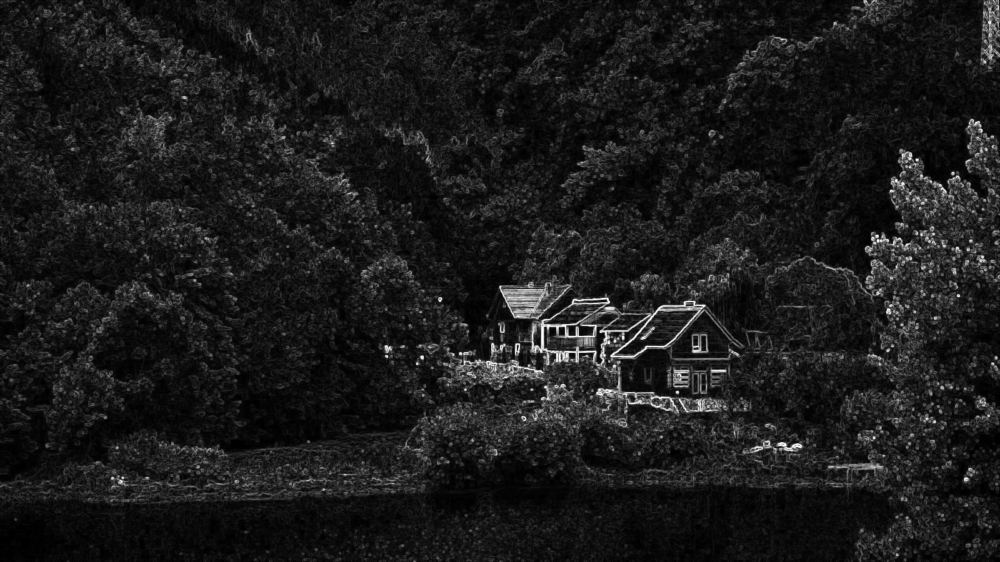

In [ ]:
#10. Phát hiện cạnh bằng Sobel và Prewitt
anh_xam = cv2.cvtColor(anh_goc, cv2.COLOR_RGB2GRAY)

sobel_x = cv2.Sobel(anh_xam, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(anh_xam, cv2.CV_64F, 0, 1, ksize=3)
anh_sobel = cv2.convertScaleAbs(cv2.magnitude(sobel_x, sobel_y))

kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]])

prewitt_x = cv2.filter2D(anh_xam, cv2.CV_32F, kernel_x)
prewitt_y = cv2.filter2D(anh_xam, cv2.CV_32F, kernel_y)
anh_prewitt = cv2.convertScaleAbs(cv2.magnitude(prewitt_x, prewitt_y))

print("Ảnh phát hiện cạnh bằng Sobel")
display(Image.fromarray(anh_sobel))
print("Ảnh phát hiện cạnh bằng Prewitt")
display(Image.fromarray(anh_prewitt))

Ảnh làm sắc nét


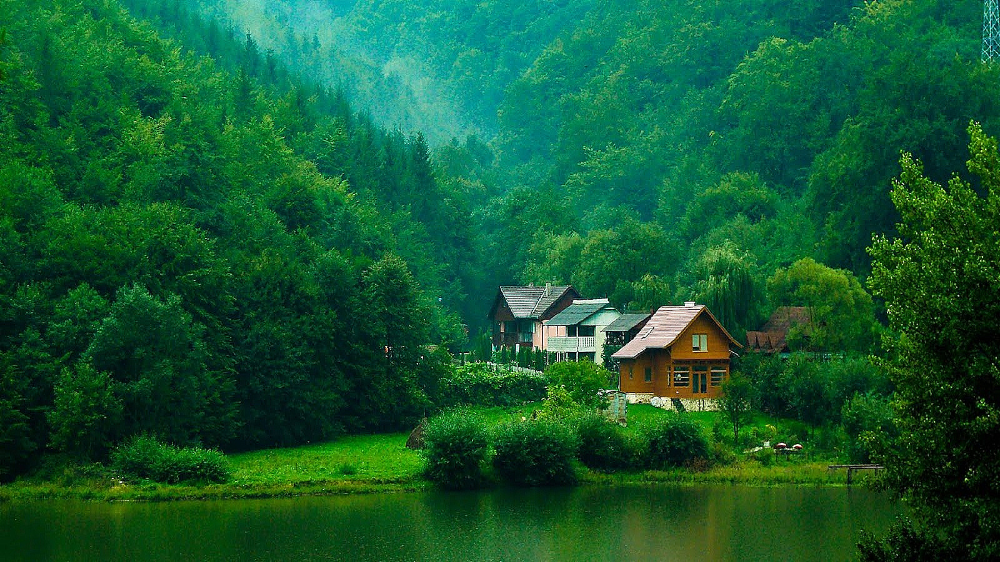

Ảnh phát hiện cạnh


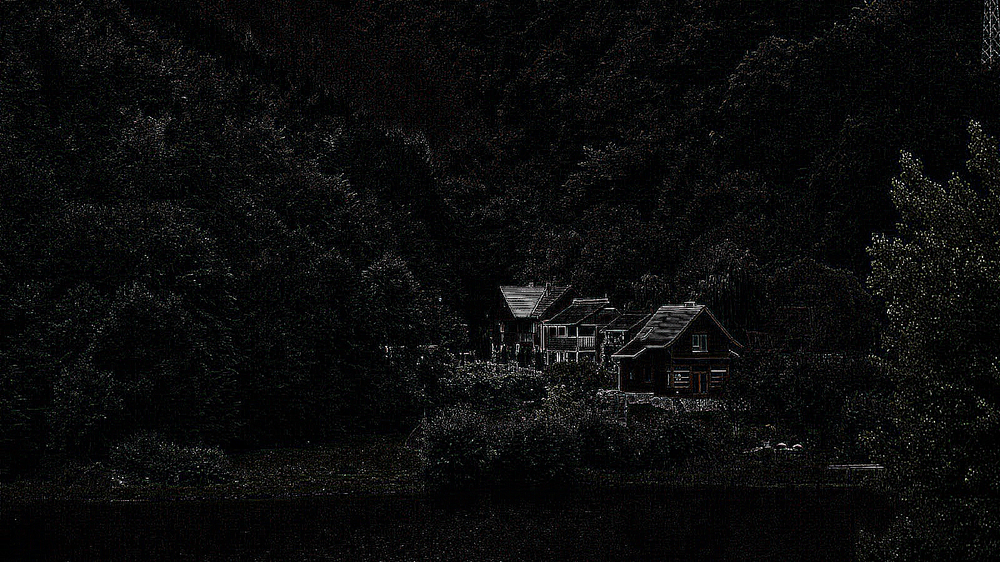

Ảnh nổi bật


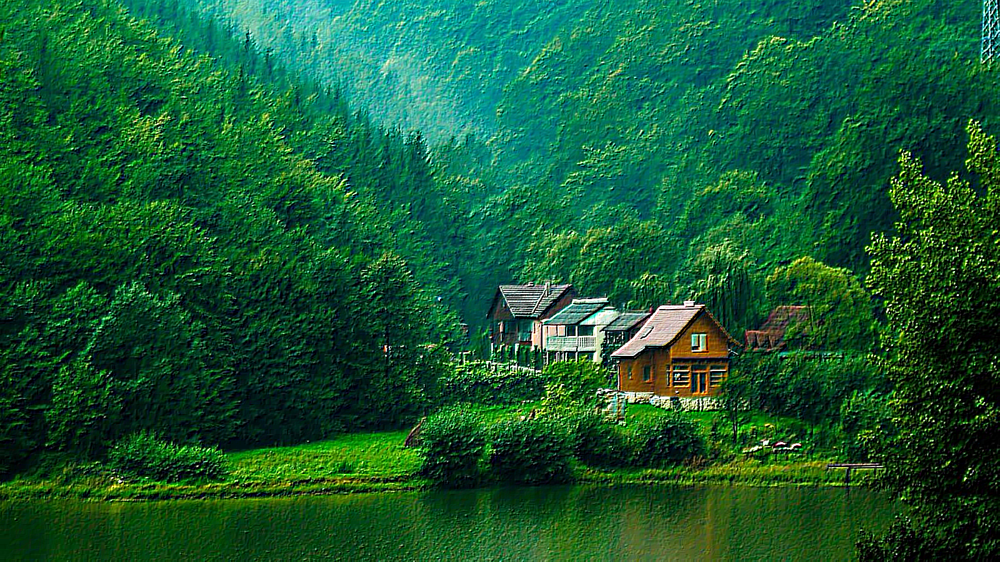

In [20]:
#11. Tự thiết kế kernel
kernel_sac_net = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
kernel_phat_hien_canh = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]])
kernel_noi_bat = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]])

anh_sac_net = cv2.filter2D(anh_goc, -1, kernel_sac_net)
anh_phat_hien_canh = cv2.filter2D(anh_goc, -1, kernel_phat_hien_canh)
anh_noi_bat = cv2.filter2D(anh_goc, -1, kernel_noi_bat)

print("Ảnh làm sắc nét")
display(Image.fromarray(anh_sac_net))
print("Ảnh phát hiện cạnh")
display(Image.fromarray(anh_phat_hien_canh))
print("Ảnh nổi bật")
display(Image.fromarray(anh_noi_bat))

Ảnh gốc


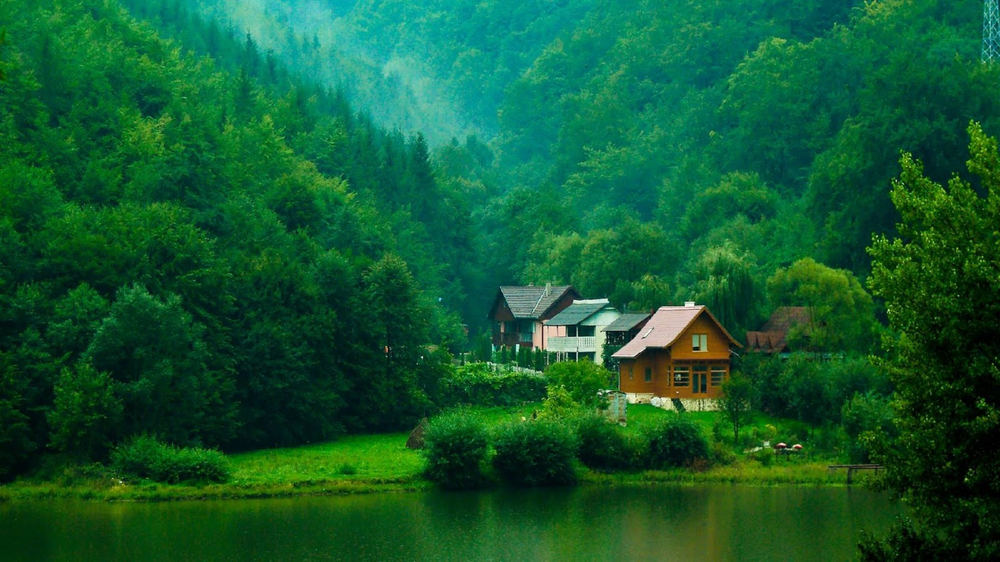

Lọc trung bình


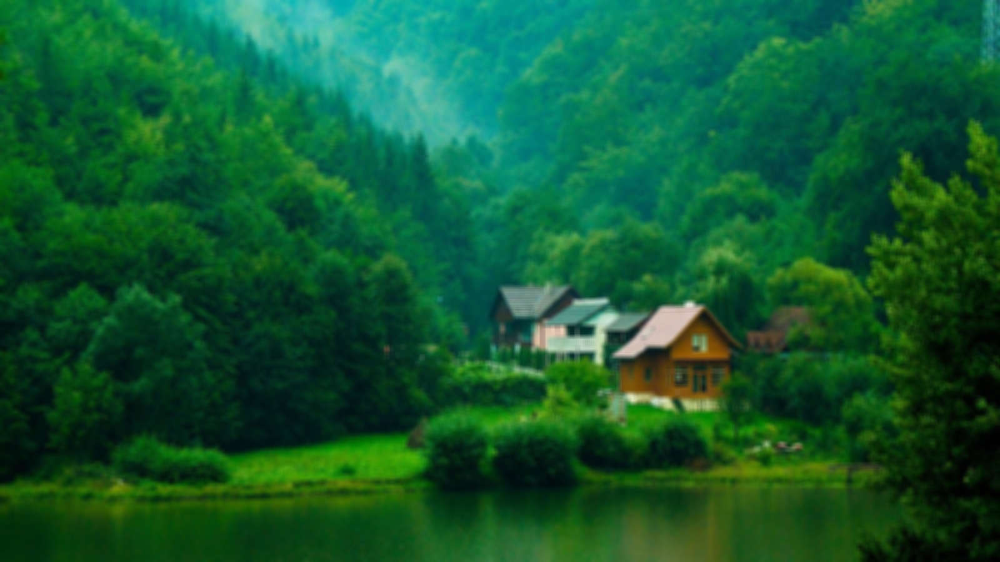

Lọc Gaussian


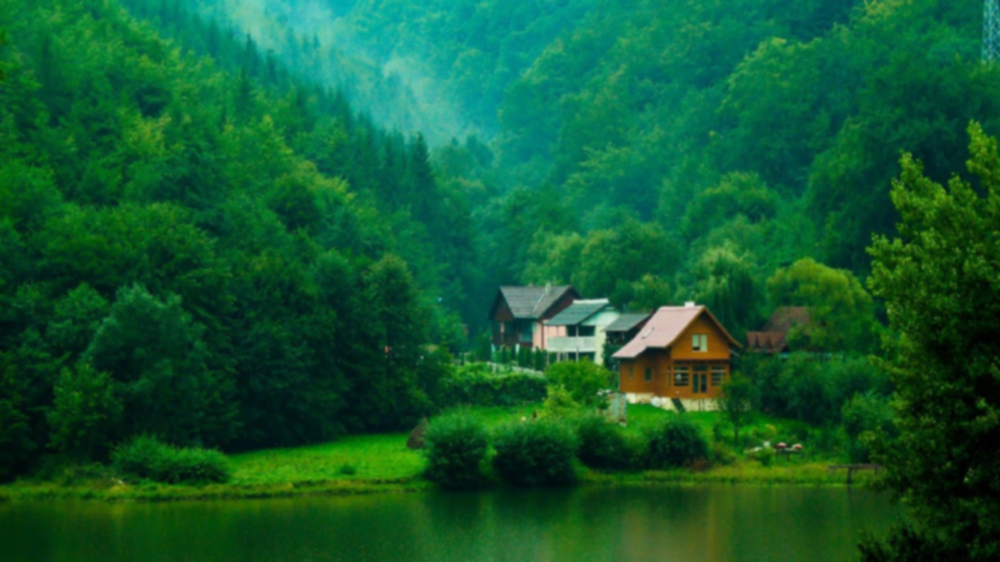

Làm sắc nét


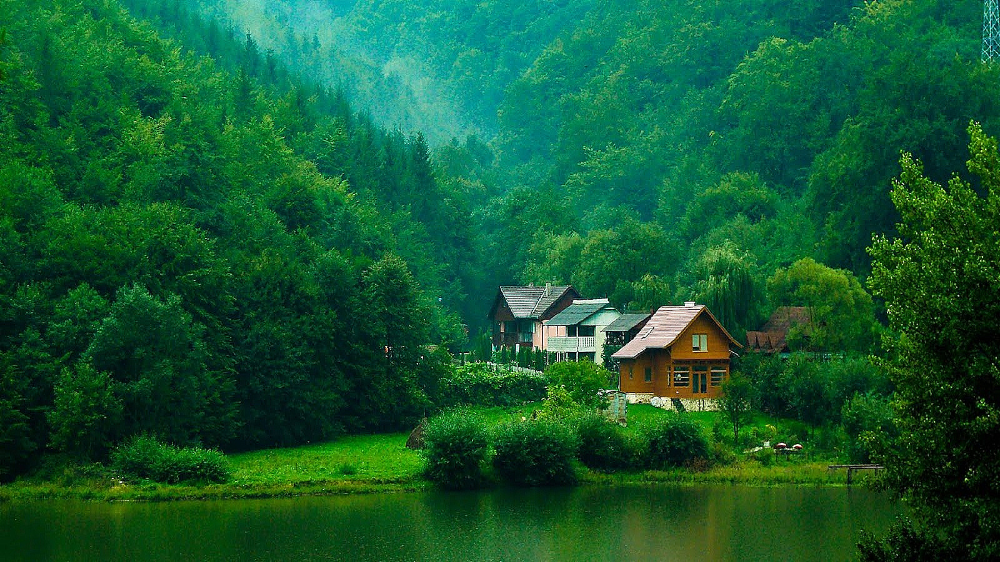

In [23]:
#12. So sánh các loại lọc
anh_mean = cv2.blur(anh_goc, (9, 9))
anh_gaussian = cv2.GaussianBlur(anh_goc, (9, 9), 0)
anh_sac_net = cv2.filter2D(anh_goc, -1, kernel_sac_net)

print("Ảnh gốc")
display(Image.fromarray(anh_goc))
print("Lọc trung bình")
display(Image.fromarray(anh_mean))
print("Lọc Gaussian")
display(Image.fromarray(anh_gaussian))
print("Làm sắc nét")
display(Image.fromarray(anh_sac_net))

Lọc trung vị (Median Filter)


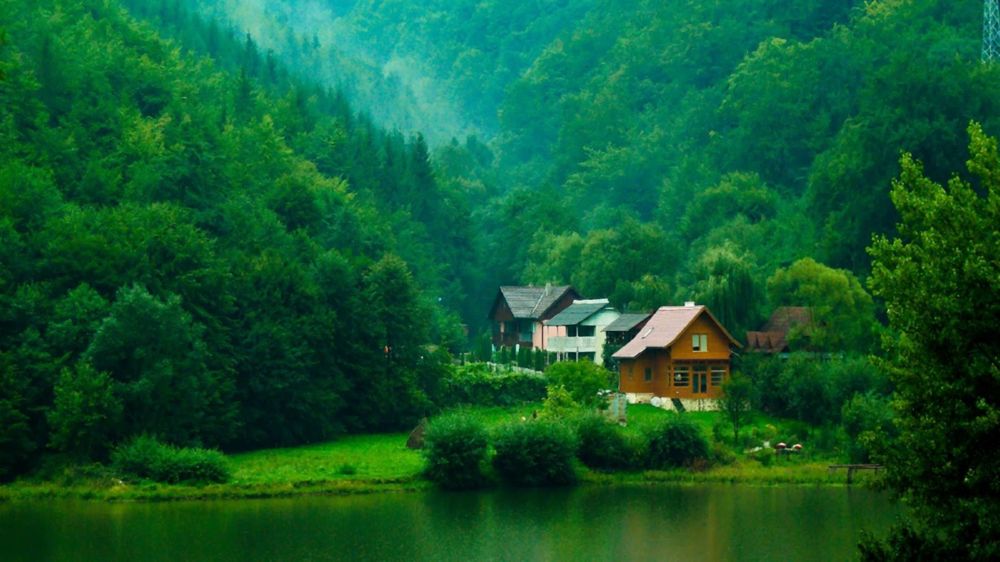

Lọc song phương (Bilateral Filter)


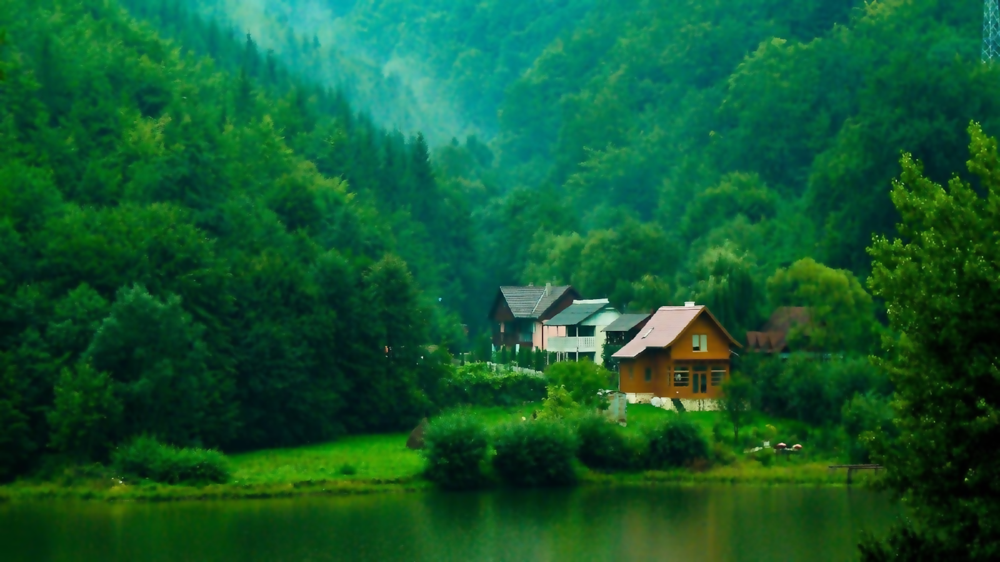

In [22]:
#13. Áp dụng lọc phi tuyến tính
anh_median = cv2.medianBlur(anh_goc, 3)
anh_bilateral = cv2.bilateralFilter(anh_goc, 9, 75, 75)

print("Lọc trung vị (Median Filter)")
display(Image.fromarray(anh_median))
print("Lọc song phương (Bilateral Filter)")
display(Image.fromarray(anh_bilateral))